# DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

Es un algoritmo de clustering que agrupa puntos basándose en la densidad de los datos. A diferencia de K-Means, DBSCAN no requiere
que se especifique el número de clusters a priori y puede identificar clusters de forma arbitraria, así como detectar puntos atípicos
(outliers).

## Características clave de DBSCAN
- No requiere que se especifique el número de clusters (k) de antemano.
- Puede identificar clusters de forma arbitraria, incluyendo formas no esféricas.
- Es capaz de detectar puntos atípicos (outliers) y tratarlos como ruido.
- Puede ser sensible a la elección de los parámetros `eps` (radio de vecindad) y `min_samples` (número mínimo de puntos para formar un cluster).
- Funciona bien con datos que tienen densidades variables, pero puede tener dificultades con clusters de densidad muy diferente.


## Ejemplo de uso de DBSCAN con scikit-learn

### Primer paso: Generación y visualización inicial de los datos

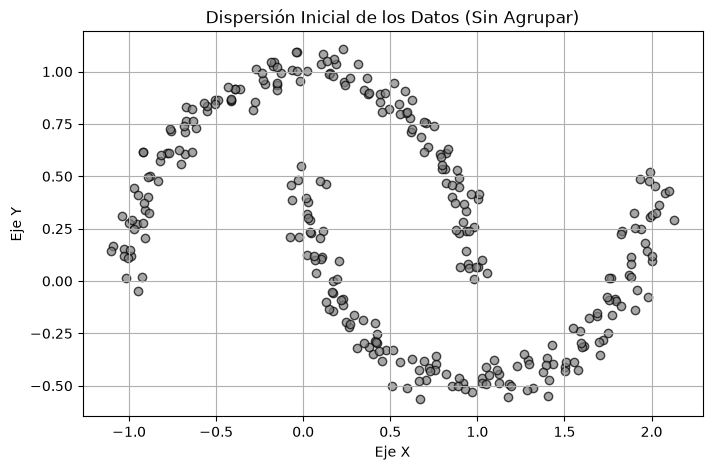

In [1]:
from scipy.stats import alpha
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
import numpy as np
import matplotlib.pyplot as plt
# Generar un conjunto de datos con forma de media luna

X, y = make_moons(n_samples=300, noise=0.05, random_state=42)

# Visualizar los datos generados
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], color='gray', alpha=0.7, edgecolors='k')
plt.title("Dispersión Inicial de los Datos (Sin Agrupar)")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.grid(True)
plt.show()

### Segundo paso: Crear y entrenar el modelo DBSCAN

In [4]:
dbscan = DBSCAN(eps=0.2, min_samples=5)
etiquetas = dbscan.fit_predict(X)

### Tercer paso: Visualización de los resultados del clustering

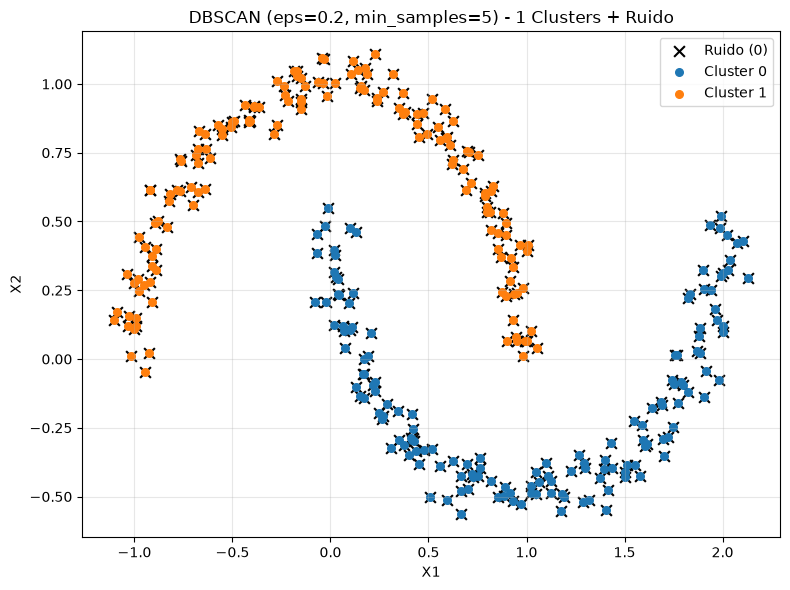

Clusters identificados: 1
Puntos de ruido: 0


In [9]:
plt.figure(figsize=(8,6))

# Separación de ruido
ruido = (etiquetas == -1)

# Gráfica del ruido
plt.scatter(X[~ruido, 0],
            X[~ruido, 1],
            color='black',
            marker='x',
            s=60,
            label=f"Ruido ({np.sum(ruido)})"
)

# Gráfica de los clusters
for k in np.unique(etiquetas):
    if k != -1:
        mascara = (etiquetas == k)
        plt.scatter(X[mascara, 0],
                    X[mascara, 1],
                    s=30,
                    label=f"Cluster {k}"
        )

plt.title(f"DBSCAN (eps=0.2, min_samples=5) - {len(np.unique(etiquetas)) - 1} Clusters + Ruido")
plt.legend()
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Salida en consola:
print(f"Clusters identificados: {len(np.unique(etiquetas)) - 1}")
print(f"Puntos de ruido: {np.sum(ruido)}")

## ¿Qué es el clustering?

El clustering es una técnica de aprendizaje no supervisado que busca agrupar un conjunto de objetos de tal manera que los objetos dentro del mismo grupo (o
cluster) sean más similares entre sí que con los de otros grupos. Es ampliamente utilizado en análisis de datos, minería de datos y aprendizaje automático para
descubrir patrones y estructuras ocultas en los datos.

### ventajas
- No requiere etiquetas de datos.
- Puede descubrir estructuras complejas en los datos.
- Es útil para explorar y entender la estructura de los datos sin necesidad de conocimiento previo.
- Permite identificar outliers o puntos atípicos en los datos.

### desventajas
- La elección del algoritmo y sus parámetros puede afectar significativamente los resultados.
- Algunos algoritmos pueden ser sensibles al ruido y a la escala de los datos.
- Puede ser computacionalmente costoso para grandes conjuntos de datos.